In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv')

df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


In [7]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [27]:
df.duplicated().sum()

np.int64(0)

# Chapter 1: The Face Behind the Numbers

![](https://i.imgur.com/EW7gaGP.jpeg)

Every story begins with people.

One quiet evening, Juno came across a dataset containing thousands of student records. At first glance, they looked like nothing more than rows of numbers and categories. But behind every row was a student with a different background, lifestyle, and experience.

Juno wondered: Who are the students behind these numbers, and what can their data reveal?

Before searching for hidden patterns, he decided to understand the people represented in the dataset. He began by exploring their ages, gender distribution, and reported depression status.

After all, every meaningful discovery starts with understanding the data.

In [9]:
# Dataset overview
total_students = len(df)

print(f"Total students: {total_students:,}")
print(f"Average age: {df['Age'].mean():.1f}")
print(f"Age range: {df['Age'].min()}–{df['Age'].max()}")
print(f"Number of semesters: {df['Current_semester'].nunique()}")

Total students: 4,464
Average age: 22.6
Age range: 17–28
Number of semesters: 14


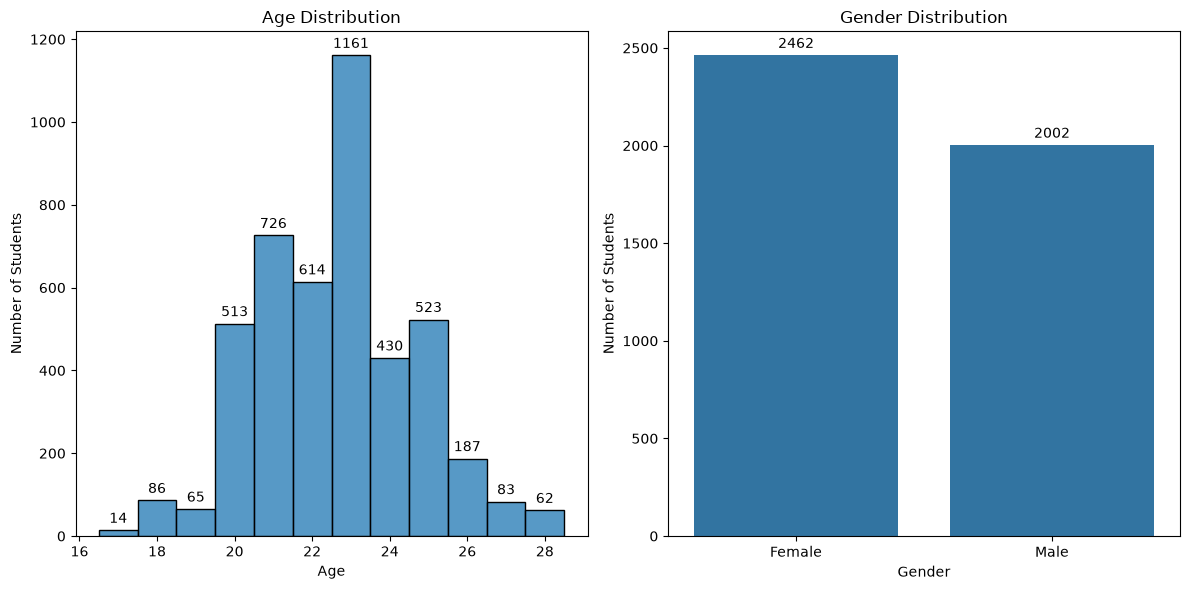

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=12,
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Students")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Gender Distribution
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1]
)
axes[1].set_title("Gender Distribution")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Students")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

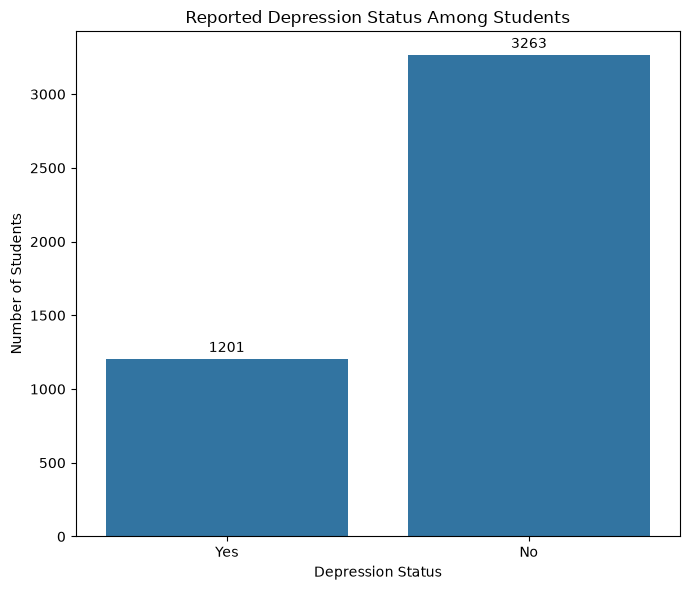

In [11]:
depression_counts = df["Depression"].value_counts()

depression_pct = (
    df["Depression"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

depression_summary = pd.DataFrame({
    "Count": depression_counts,
    "Percentage": depression_pct
})

plt.figure(figsize=(7, 6))

ax = sns.countplot(
    data=df,
    x="Depression"
)

# Add count labels above each bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_title("Reported Depression Status Among Students")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

# Chapter 2: Searching for Hidden Patterns

![](https://i.imgur.com/Rda6hsp.jpeg)

Juno had seen the bigger picture. Thousands of students, different backgrounds, and one finding that caught his attention: 26.9% of the students were labeled as experiencing depression.

But the numbers alone couldn’t tell him much.

He began to wonder whether students’ lives shared any patterns. Could family background, relationship status, or living conditions be associated with differences in reported depression status?

To find out, Juno decided to look beyond the overall numbers and compare groups of students.

**Perhaps the clues weren’t hidden in individual records, but in the patterns connecting them.**

In [ ]:
def plot_depression_comparison(column, title, order=None):
    colors = {"No": "tab:blue", "Yes": "tab:orange"}

    # Define one consistent category order for both charts
    if order is None:
        order = df[column].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Count
    sns.countplot(
        data=df,
        x=column,
        hue="Depression",
        order=order,
        hue_order=["No", "Yes"],
        palette=colors,
        ax=axes[0]
    )

    axes[0].set_title(f"Number of students by {title} and Depression Status")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Number of Students")
    axes[0].tick_params(axis="x", rotation=15)

    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.0f", padding=3, fontsize=8
        )

    # Percentage
    pct = pd.crosstab(
        df[column], df["Depression"], normalize="index"
    ).mul(100).reindex(index=order, columns=["No", "Yes"], fill_value=0)

    pct.plot(
        kind="bar",
        color=[colors["No"], colors["Yes"]],
        ax=axes[1]
    )

    axes[1].set_title(f"Depression rate within each {title} (%)")
    axes[1].set_xlabel(title)
    axes[1].set_ylabel("Percentage of Students")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Depression Status")

    for container in axes[1].containers:
        axes[1].bar_label(
            container, fmt="%.1f%%", padding=3, fontsize=8
        )

    plt.tight_layout()
    plt.show()

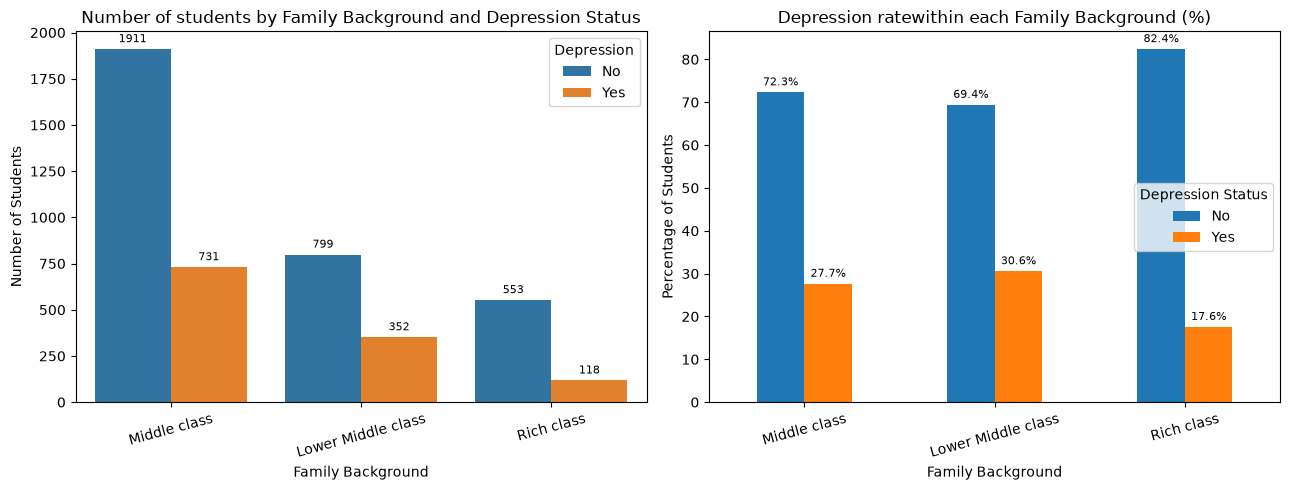

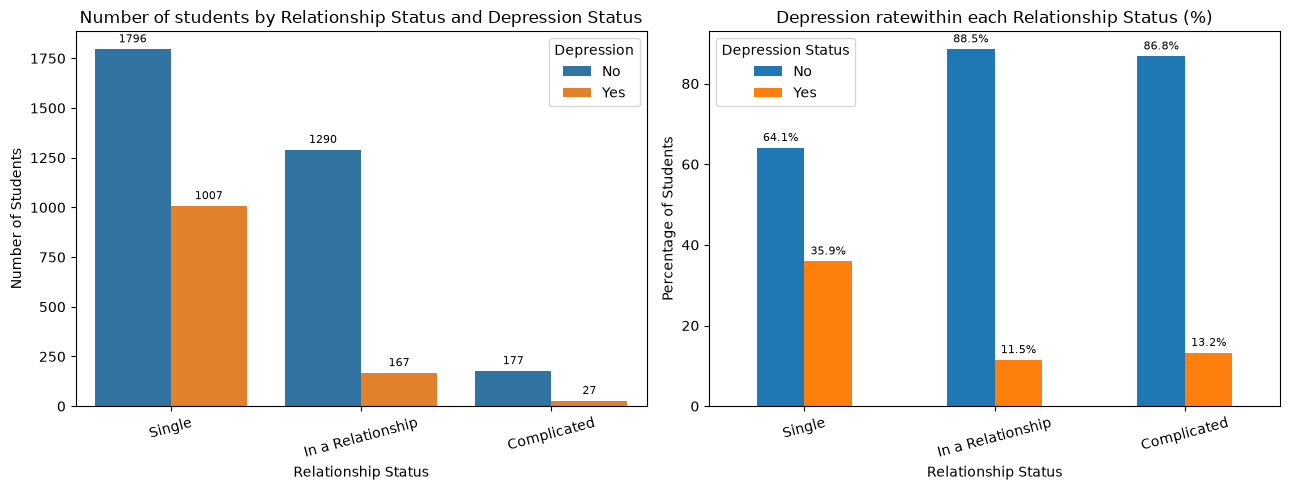

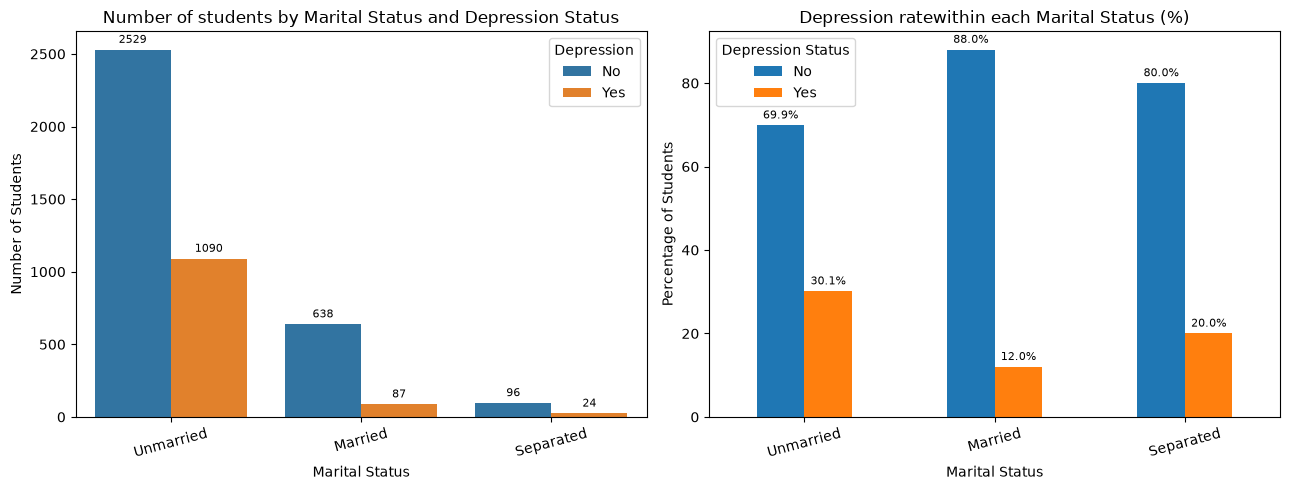

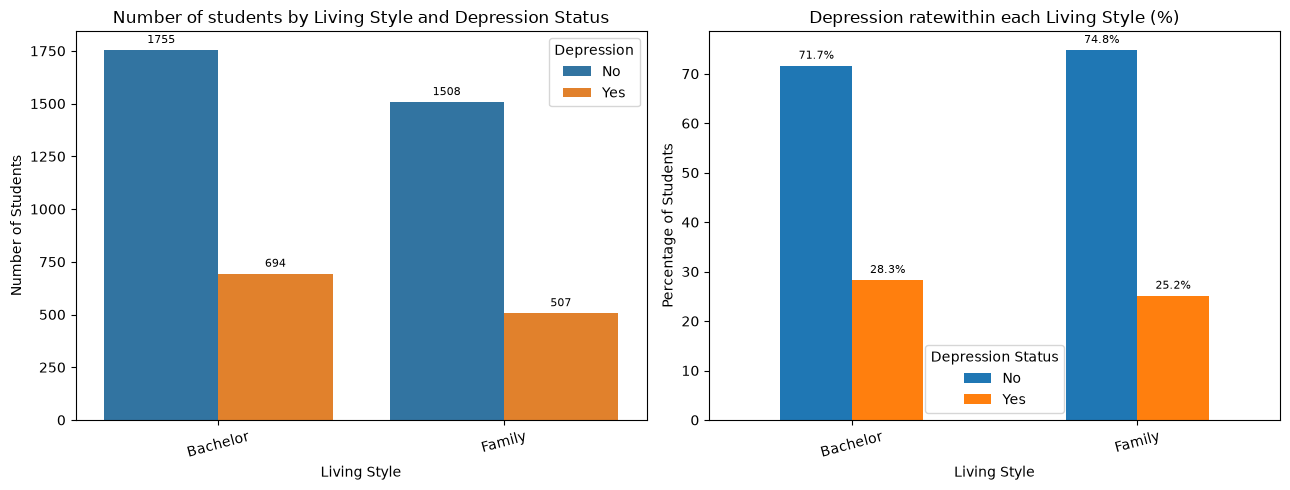

In [25]:
#1 colonna da usare
#2 titolo
plot_depression_comparison("Family_background", "Family Background")
plot_depression_comparison("Relationship_status", "Relationship Status")
plot_depression_comparison("Marital_status", "Marital Status")
plot_depression_comparison("Living_style", "Living Style")

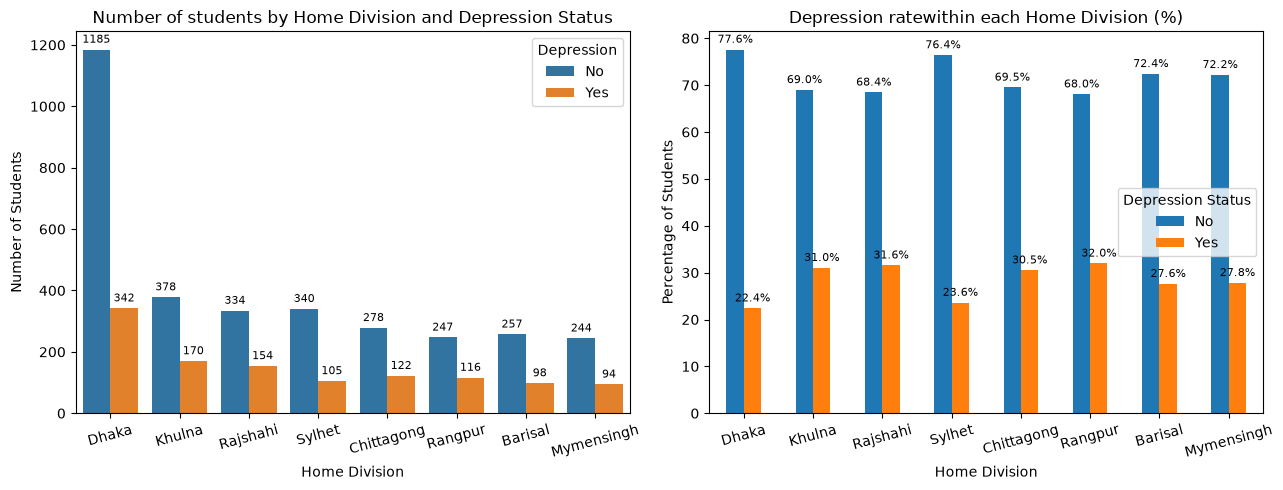

In [26]:
plot_depression_comparison("Home_division", "Home Division")


I grafici a destra mostrano la percentuale di depressi e non depressi (come si distribuisce la depressione dentro ogni classe).



As Juno compared the students, several patterns began to emerge. Single and unmarried students had higher proportions of reported depression, while students from lower-middle-class backgrounds showed a higher proportion than those from rich-class backgrounds. Students categorized as living as a bachelor also showed a slightly higher proportion than those living with family.

Among these comparisons, relationship status showed the most noticeable difference. But Juno knew that a pattern was not the same as an explanation. These findings could reveal associations, not prove what causes depression.

His investigation had uncovered a few promising clues. Now, he wanted to look beyond individual characteristics and explore what other factors might help explain the differences.

The patterns were beginning to take shape, but Juno’s investigation was far from over.

# Chapter 3: Beyond the Classroom

![](https://i.imgur.com/NSp9gVr.jpeg)

Juno had explored the students’ backgrounds and discovered several intriguing patterns. But he wondered whether their experiences inside the classroom might reveal something more.

Academic life comes with its own challenges. Students move through different semesters, work toward academic goals, and receive grades that reflect their performance.

Could academic standing be associated with differences in reported depression status?

Juno decided to investigate two variables: current semester and CGPA. Perhaps examining their academic journey would reveal another piece of the puzzle.

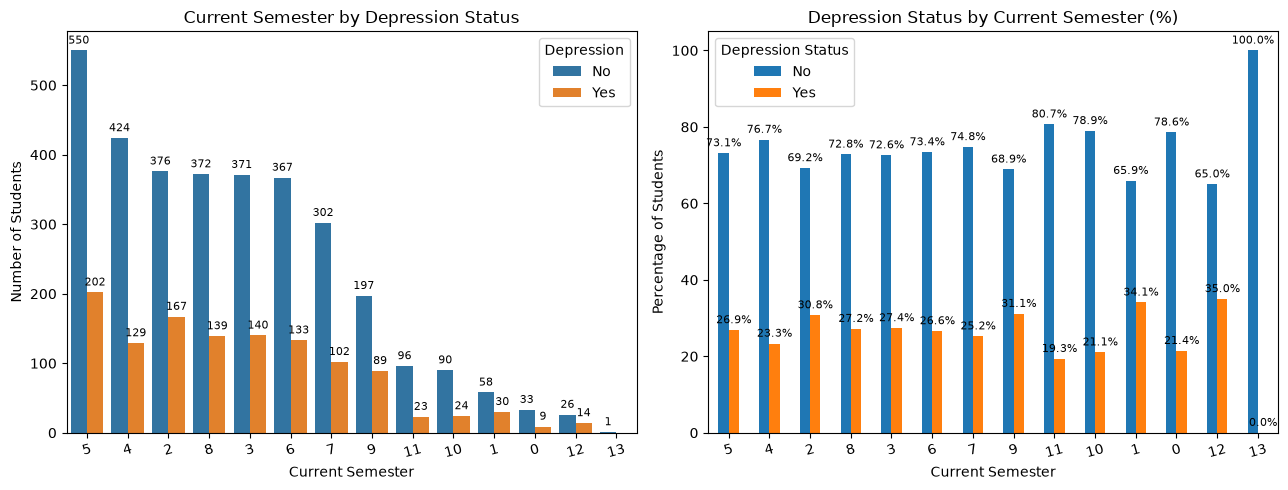

In [14]:
plot_depression_comparison("Current_semester", "Current Semester")

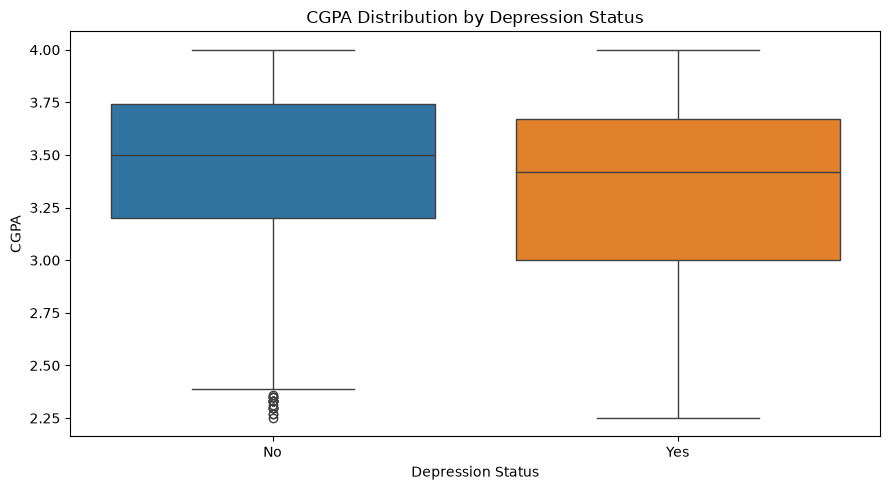

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("CGPA Distribution by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("CGPA")

plt.tight_layout()
plt.show()

Juno found that students labeled as experiencing depression had a slightly lower median CGPA (3.42) than those labeled as not experiencing depression (3.50). The difference was modest, suggesting that academic performance alone might not tell the whole story.

He also noticed that the proportion of students labeled as experiencing depression varied across semesters, ranging from 19.33% to 35.00%. However, some semesters had far fewer students than others, making direct comparisons less reliable.

These patterns offered new clues, but they did not establish that academic performance or semester progression caused depression. Juno realized that understanding students’ experiences required looking beyond academic indicators.

His investigation continued. This time, he would explore the role of health, social connections, and financial circumstances.

# Chapter 4: The Bigger Picture

![](https://i.imgur.com/Uds62aT.jpeg)

Juno had explored students’ backgrounds, relationships, and academic performance. Yet, he suspected that other aspects of their daily lives might reveal more clues.

Health, friendships, and financial circumstances can all be important parts of a student’s experience. But could the data reveal any patterns connecting these factors with reported depression status?

Juno decided to investigate three more variables: health condition, friend circle, and study-related costs.

Perhaps the answers weren’t just in the classroom, but in the world surrounding each student.

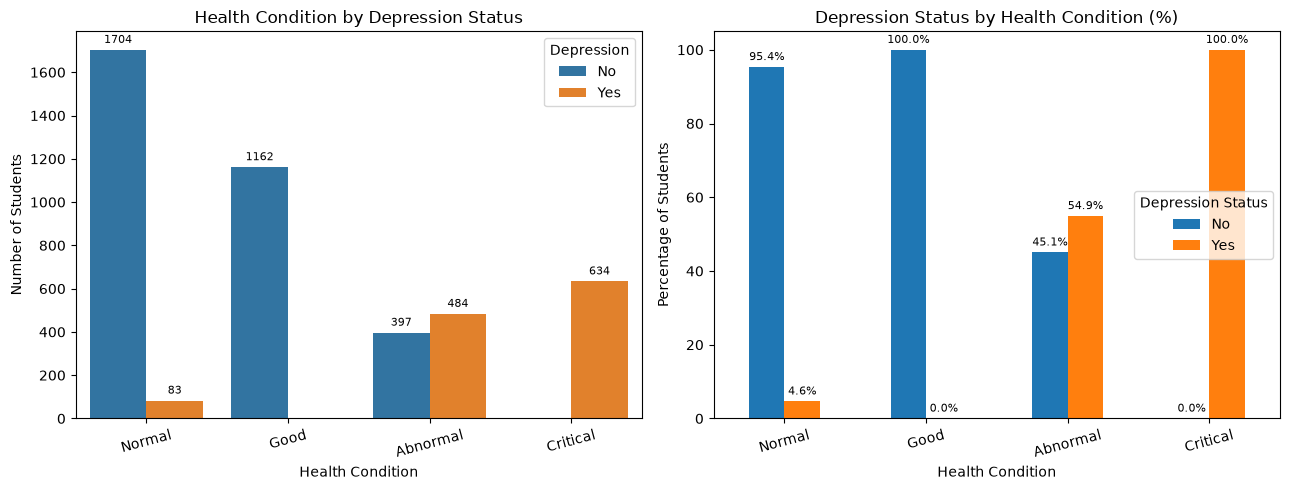

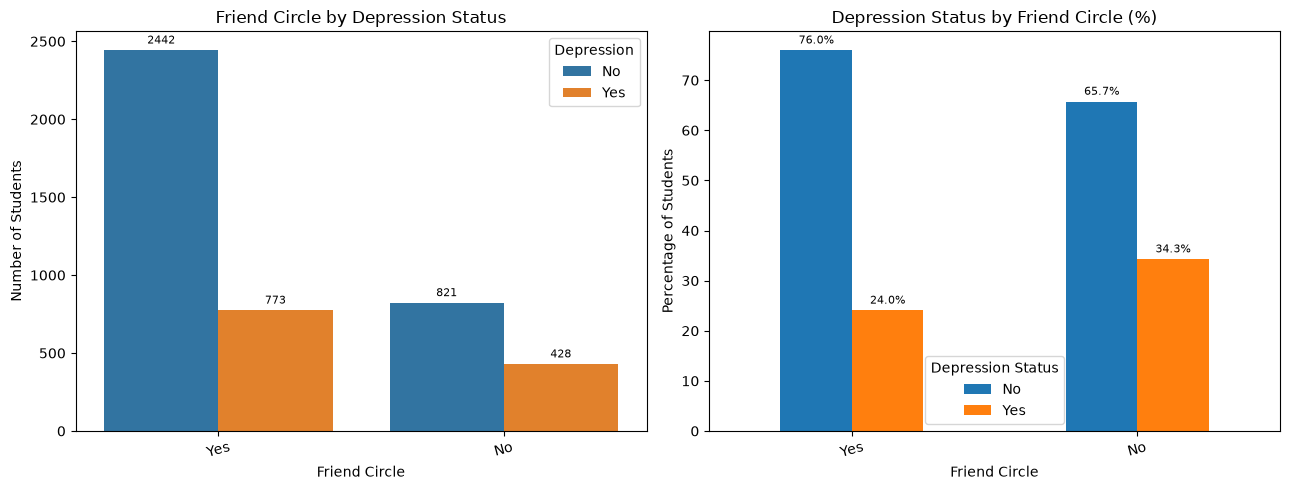

In [16]:
plot_depression_comparison("Health_condition", "Health Condition")
plot_depression_comparison("friend_circle", "Friend Circle")

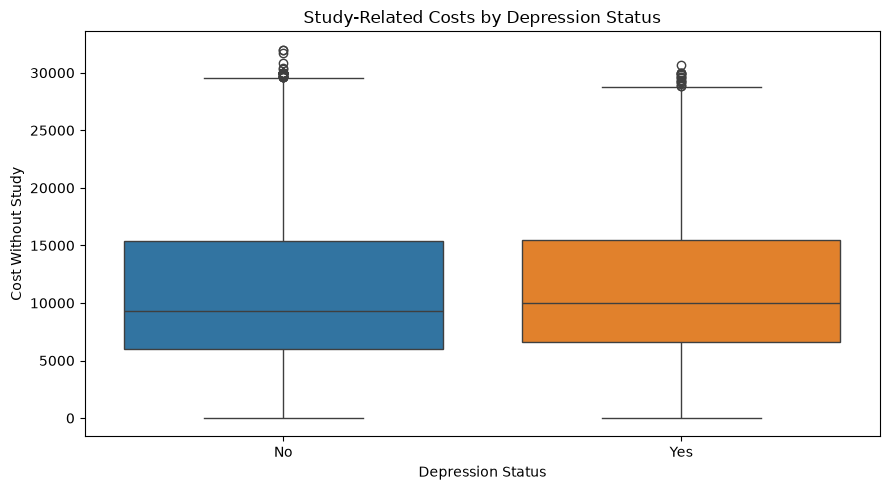

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="Cost_without_study",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("Study-Related Costs by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Cost Without Study")

plt.tight_layout()
plt.show()

Juno uncovered several patterns in students’ daily lives. Health condition showed the most striking differences: all students categorized as Critical were labeled as experiencing depression, while none categorized as Good received that label. This unusual separation made him question how these categories were defined and how they related to the dataset’s depression labels.

He also found that students without a friend circle had a higher proportion of reported depression, while study-related costs showed only modest differences between groups.

Juno realized that not every pattern tells the full story. Some findings might reflect how the data was collected or categorized, and associations alone cannot establish cause and effect.

With these clues in hand, Juno was ready to connect the findings and decide what the data could reveal.

# Chapter 5: Connecting the Dots

![](https://i.imgur.com/zudVsuJ.jpeg)

Juno had explored the students’ backgrounds, relationships, academic performance, health conditions, social connections, and financial circumstances.

Across thousands of records, several patterns had emerged. Some differences were subtle, while others were surprisingly strong.

But Juno knew that finding patterns was only part of the investigation. He needed to step back, connect the evidence, and ask a more important question:

What can these numbers genuinely tell us about students’ reported depression status?

This time, instead of searching for more clues, Juno would examine the findings as a whole—and recognize the limits of what the data could explain.

In [38]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

summary_list = []

for col in categorical_columns:
    tab = pd.crosstab(df[col], df['Depression'])
    tab['Count'] = tab['No'] + tab['Yes']
    tab['Depression_Rate'] = tab['Yes'] / tab['Count'] *100
    summary = tab.reset_index()
    summary['Variable'] = col
    summary = summary.rename(columns={col:'Category'})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category","Count", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))

           Variable           Category  Count  Depression_Rate
   Health_condition           Critical    634           100.00
   Health_condition           Abnormal    881            54.94
Relationship_status             Single   2803            35.93
      friend_circle                 No   1249            34.27
      Home_division            Rangpur    363            31.96
      Home_division           Rajshahi    488            31.56
      Home_division             Khulna    548            31.02
  Family_background Lower Middle class   1151            30.58
      Home_division         Chittagong    400            30.50
     Marital_status          Unmarried   3619            30.12
       Living_style           Bachelor   2449            28.34
      Home_division         Mymensingh    338            27.81
  Family_background       Middle class   2642            27.67
      Home_division            Barisal    355            27.61
             Gender               Male   2002          

Conoscere la colonna mi aiuta a prevedere se lo studente è depresso? Mi aspetti che se la risposta è si, i gruppi avranno percentuali diverse fra loro.
Ordiniamo l'output 

In [39]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df["Depression"]) #di nuovo tabella yes/no per ogni categoria

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum() #trasformiamo la tabella in griglia di numeri
    r, k = contingency_table.shape #righe e colonne. le assegnamo (ogni colonna prenderà questi valori)


    denominator = n * min(r - 1, k - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan
    if cramers_v <0.1:
        strength = 'Negligible'
    elif cramers_v <0.3:
        strength = 'Weak'
    elif cramers_v < 0.5:
        strength = 'Moderate'
    else:
        strength = 'Strong'

    p_corrected = min(p_value * len(categorical_columns), 1)
    
    association_results.append({
        "Variable": col,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3),
        "Strength": strength,
        "P-value (corrected)": p_corrected,

    })

association_table = pd.DataFrame(association_results)

for nome_colonna in ["P-value", "P-value (corrected)"]:
    association_table[nome_colonna] = association_table[nome_colonna].map(
        lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
    )

association_table = association_table.sort_values("Cramer's V", ascending=False)
print(association_table.to_string(index=False))

           Variable  Chi-square  Degrees of Freedom P-value  Cramer's V   Strength P-value (corrected)
   Health_condition     2952.51                   3 < 0.001       0.813     Strong             < 0.001
Relationship_status      312.06                   2 < 0.001       0.264       Weak             < 0.001
     Marital_status      103.82                   2 < 0.001       0.153       Weak             < 0.001
      friend_circle       47.29                   1 < 0.001       0.103       Weak             < 0.001
  Family_background       38.33                   2 < 0.001       0.093 Negligible             < 0.001
      Home_division       35.92                   7 < 0.001       0.090 Negligible             < 0.001
       Living_style        5.51                   1   0.019       0.035 Negligible               0.151
             Gender        0.22                   1   0.641       0.007 Negligible               1.000


più il chi2 è alto --> più i numeri veri sono lontani da quelli attesi
p-value -_> probabulità che sia un caso (se <0.05 il legame è reale)



Applicata correzioni di Bonferroni per accountare la probabilità di trovare almeno un risultato sbagliato lungo gli 8 test. Non cambia nulla nell'interpretazione, cioò che era significativo prima lo rimane anche adesso

Mann-Whitney è un test per confrontare due gruppi su una variabile numerica. (NB. qua i due gruppi sono i depressi e i non depressi)

Dobbiamo chiederci se la differenza che vedo tra i due gruppi è reale o può essere dovuta al caso

Diverso dal chi-quadro, perchè  il chi-quadro lo fa su categorie, qua lo facciamo sui numeri

Il test sostanziamente mette in fila tutti i risultati, e controlla se un gruppo sta sistematicamente più in basso o viceversa

In [42]:
from scipy.stats import mannwhitneyu
import pandas as pd

numeric_columns = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

results = []

for col in numeric_columns:
    no_group = df.loc[df["Depression"] == "No", col]
    yes_group = df.loc[df["Depression"] == "Yes", col]
#ad esempio, per col 'CGPA' no_group conterrà i CGPA dei non depressi mentre yes_group que
    statistic, p_value = mannwhitneyu(
        no_group,
        yes_group,
        alternative="two-sided"
    )
#statistic è il numero di coppie in cui il non depresso ha il valore più alto
    results.append({
        "Variable": col,
        "Median (No)": no_group.median(),
        "Median (Yes)": yes_group.median(),
        "Mean (No)": no_group.mean(),
        "Mean (Yes)": yes_group.mean(),
        "U Statistic": statistic,
        "P-value": p_value
    })

numeric_association_table = pd.DataFrame(results)

numeric_association_table["P-value"] = (
    numeric_association_table["P-value"]
    .map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
)

numeric_association_table[
    ["Median (No)", "Median (Yes)", "Mean (No)", "Mean (Yes)", "U Statistic"]
] = numeric_association_table[
    ["Median (No)", "Median (Yes)", "Mean (No)", "Mean (Yes)", "U Statistic"]
].round(2)

numeric_association_table

,Variable,Median (No),Median (Yes),Mean (No),Mean (Yes),U Statistic,P-value
0,Age,23.0,23.00,22.66,22.51,2057404.0,0.009
1,Current_semester,5.0,5.00,5.43,5.33,2003439.5,0.246
2,CGPA,3.5,3.42,3.44,3.35,2195667.0,< 0.001
3,Cost_without_study,9300.0,10000.00,11169.58,11442.40,1871265.0,0.021


In [41]:
# Variables selected for student profile analysis
profile_columns = [
    "Relationship_status",
    "friend_circle",
    "Family_background",
    "Living_style"
]

target = "Depression"

# Create student profiles from combinations of categorical variables
profile_summary = (
    df.groupby(profile_columns, observed=True)
    .agg(
        Total_Students=("Depression", "size"),
        Depression_Count=("Depression", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

# Calculate the percentage labeled as experiencing depression
profile_summary["Depression_Rate"] = (
    profile_summary["Depression_Count"]
    / profile_summary["Total_Students"]
    * 100
)

# Keep profiles with at least 20 students for more stable comparisons
profile_summary = profile_summary[
    profile_summary["Total_Students"] >= 20
].copy()

profile_summary["Depression_Rate"] = (
    profile_summary["Depression_Rate"].round(2)
)

profile_summary = profile_summary.sort_values(
    "Depression_Rate",
    ascending=False
)

profile_summary.head(10)

,Relationship_status,friend_circle,Family_background,Living_style,Total_Students,Depression_Count,Depression_Rate
26,Single,No,Middle class,Bachelor,202,100,49.50
25,Single,No,Lower Middle class,Family,76,37,48.68
24,Single,No,Lower Middle class,Bachelor,95,42,44.21
27,Single,No,Middle class,Family,305,134,43.93
31,Single,Yes,Lower Middle class,Family,115,47,40.87
33,Single,Yes,Middle class,Family,442,160,36.20
29,Single,No,Rich class,Family,46,16,34.78
32,Single,Yes,Middle class,Bachelor,655,218,33.28
30,Single,Yes,Lower Middle class,Bachelor,623,195,31.30
3,Complicated,No,Middle class,Family,29,8,27.59


Looking Beyond Individual Characteristics

Juno had examined each characteristic separately, but he wondered what would happen when he considered several characteristics together.

He combined relationship status, friend circle, family background, and living style to compare different student profiles. To make the comparisons more meaningful, he included only profiles representing at least 20 students.

One profile stood out: single students without a friend circle, from middle-class backgrounds, and living as bachelors had the highest reported depression rate among the ten profiles examined. Of the 202 students in this group, 100 were labeled as experiencing depression—a rate of 49.50%.

Other profiles of single students without a friend circle also showed relatively high rates, including 48.68% among those from lower-middle-class backgrounds who lived with family.

These findings suggested that the observed rates varied across combinations of student characteristics. However, the results were descriptive, not proof that any particular characteristic caused depression. The profiles also differed in size, so smaller groups required greater caution when interpreting their percentages.

Juno had discovered that examining characteristics together could reveal patterns that were less apparent when each variable was considered alone.

![](https://i.imgur.com/VNErnnC.jpeg)

After examining thousands of student records, Juno began to connect the clues.

Relationship status showed the strongest association with reported depression status among the categorical variables examined, excluding health condition. Students’ CGPA and study-related costs also differed statistically between the two groups, although the median differences were relatively small. Current semester showed no statistically significant difference.

By combining four characteristics, Juno also identified student profiles with reported depression rates approaching 50%, compared with the overall dataset rate of 26.9%. These findings offered new perspectives on how reported depression status varied across groups.

Yet, Juno understood that the data had limitations. Associations could not establish causation, and group-level percentages could not predict an individual’s mental health. The unusually strong relationship between health-condition categories and depression labels also raised questions about how the data had been constructed.

Ultimately, Juno learned that data analysis was not simply about finding patterns. It was about questioning the evidence, interpreting results carefully, and being honest about what remained unknown.

The numbers had given Juno clues, not all the answers. Sometimes, the most meaningful discovery was understanding the limits of what the data could reveal.